In [2]:
# ============================
# TAREA 5 - PARTE A (Fraude)
# Bloque A0: Imports y config
# ============================

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    confusion_matrix,
    roc_auc_score
)

from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE

RANDOM_STATE = 42
THRESHOLD = 0.5

plt.style.use("default")  # opcional, por si quieres estilo limpio


In [5]:
# =======================================
# Celda A1: Carga de datos y train/test
# =======================================

df = pd.read_csv("creditcard.csv")

print("Dimensiones del dataset:", df.shape)
print(df.head())

y = df["Class"].astype(int)
X = df.drop("Class", axis=1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    stratify=y,
    random_state=RANDOM_STATE
)

print("\nTamaño TRAIN:", X_train.shape)
print("Tamaño TEST:", X_test.shape)


Dimensiones del dataset: (284807, 31)
   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.20601

In [6]:
# ======================================
# Celda A2: Evidencia de desbalance
# ======================================

print("Conteo de clases (global):")
print(y.value_counts())

print("\nProporción de clases (global):")
print(y.value_counts(normalize=True))


Conteo de clases (global):
Class
0    284315
1       492
Name: count, dtype: int64

Proporción de clases (global):
Class
0    0.998273
1    0.001727
Name: proportion, dtype: float64


Varianza explicada por PC1 y PC2: [0.06543803 0.05606646]


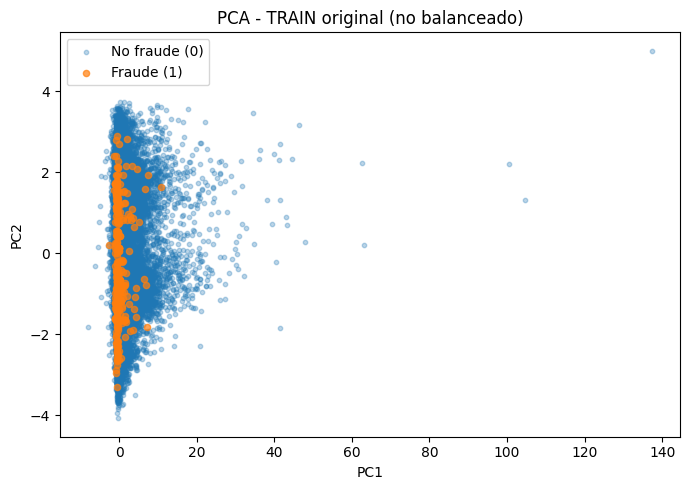

In [8]:
# ===========================================
# Celda A3: PCA sobre el TRAIN original
# ===========================================

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_train_pca = pca.fit_transform(X_train_scaled)

print("Varianza explicada por PC1 y PC2:", pca.explained_variance_ratio_)

plt.figure(figsize=(7, 5))
plt.scatter(
    X_train_pca[y_train == 0, 0],
    X_train_pca[y_train == 0, 1],
    alpha=0.3,
    s=10,
    label="No fraude (0)"
)
plt.scatter(
    X_train_pca[y_train == 1, 0],
    X_train_pca[y_train == 1, 1],
    alpha=0.7,
    s=20,
    label="Fraude (1)"
)
plt.title("PCA - TRAIN original (no balanceado)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.tight_layout()
plt.show()


In [9]:
# =======================================
# Celda A4: Balanceo en el TRAIN
# =======================================

rus = RandomUnderSampler(random_state=RANDOM_STATE)
ros = RandomOverSampler(random_state=RANDOM_STATE)
smote = SMOTE(random_state=RANDOM_STATE)

X_train_rus, y_train_rus = rus.fit_resample(X_train_scaled, y_train)
X_train_ros, y_train_ros = ros.fit_resample(X_train_scaled, y_train)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print("Tamaño TRAIN original:", X_train_scaled.shape, "Clases:", np.bincount(y_train))
print("Tamaño TRAIN undersampling:", X_train_rus.shape, "Clases:", np.bincount(y_train_rus))
print("Tamaño TRAIN oversampling:", X_train_ros.shape, "Clases:", np.bincount(y_train_ros))
print("Tamaño TRAIN SMOTE:", X_train_smote.shape, "Clases:", np.bincount(y_train_smote))


Tamaño TRAIN original: (199364, 30) Clases: [199020    344]
Tamaño TRAIN undersampling: (688, 30) Clases: [344 344]
Tamaño TRAIN oversampling: (398040, 30) Clases: [199020 199020]
Tamaño TRAIN SMOTE: (398040, 30) Clases: [199020 199020]


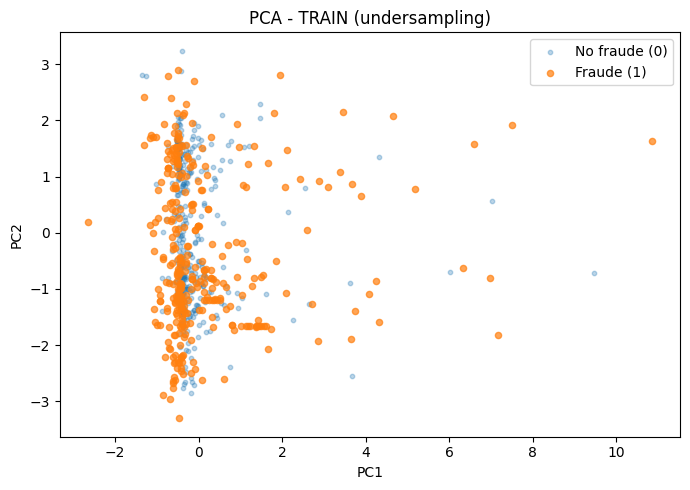

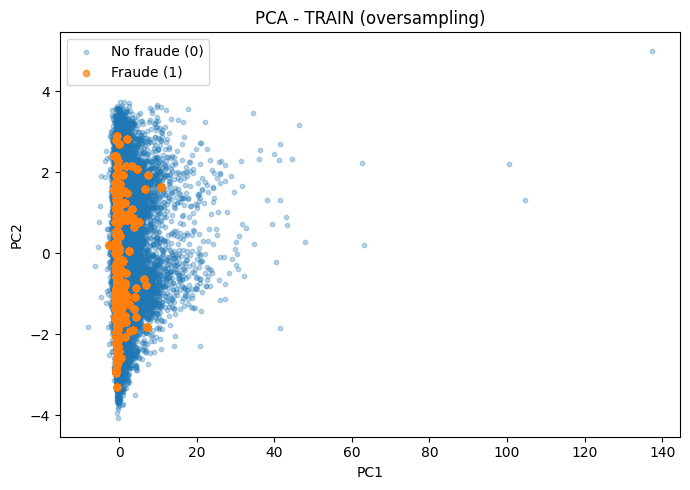

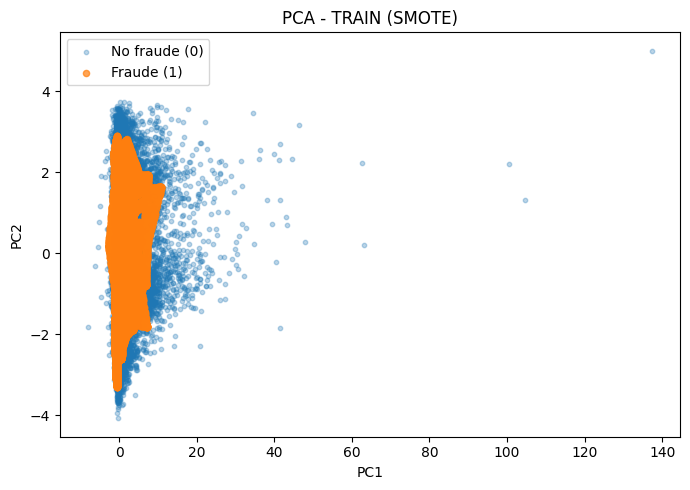

In [10]:
# =======================================
# Celda A5: PCA de TRAIN balanceados
# =======================================

X_train_rus_pca = pca.transform(X_train_rus)
X_train_ros_pca = pca.transform(X_train_ros)
X_train_smote_pca = pca.transform(X_train_smote)

def plot_pca_balanceado(X_pca, y_res, titulo):
    plt.figure(figsize=(7, 5))
    plt.scatter(
        X_pca[y_res == 0, 0],
        X_pca[y_res == 0, 1],
        alpha=0.3,
        s=10,
        label="No fraude (0)"
    )
    plt.scatter(
        X_pca[y_res == 1, 0],
        X_pca[y_res == 1, 1],
        alpha=0.7,
        s=20,
        label="Fraude (1)"
    )
    plt.title(titulo)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_pca_balanceado(X_train_rus_pca,   y_train_rus,   "PCA - TRAIN (undersampling)")
plot_pca_balanceado(X_train_ros_pca,   y_train_ros,   "PCA - TRAIN (oversampling)")
plot_pca_balanceado(X_train_smote_pca, y_train_smote, "PCA - TRAIN (SMOTE)")


In [11]:
# =====================================================
# Celda A6: Modelado RF y métricas en TEST
# =====================================================

def evaluar_modelo_fraude(y_true, y_proba, threshold=0.5):
    y_pred = (y_proba >= threshold).astype(int)
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Sensitivity_fraude": sensitivity,
        "Specificity_no_fraude": specificity,
        "AUC_ROC": roc_auc_score(y_true, y_proba),
        "CM": cm,
        "y_pred": y_pred,
        "y_proba": y_proba
    }

resultados = {}

# RF con TRAIN original
rf_original = RandomForestClassifier(
    n_estimators=300,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
rf_original.fit(X_train_scaled, y_train)
y_proba_orig = rf_original.predict_proba(X_test_scaled)[:, 1]
resultados["RF_original"] = evaluar_modelo_fraude(y_test, y_proba_orig, THRESHOLD)

# RF con TRAIN undersample
rf_rus = RandomForestClassifier(
    n_estimators=300,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
rf_rus.fit(X_train_rus, y_train_rus)
y_proba_rus = rf_rus.predict_proba(X_test_scaled)[:, 1]
resultados["RF_undersample"] = evaluar_modelo_fraude(y_test, y_proba_rus, THRESHOLD)

# RF con TRAIN oversample
rf_ros = RandomForestClassifier(
    n_estimators=300,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
rf_ros.fit(X_train_ros, y_train_ros)
y_proba_ros = rf_ros.predict_proba(X_test_scaled)[:, 1]
resultados["RF_oversample"] = evaluar_modelo_fraude(y_test, y_proba_ros, THRESHOLD)

# RF con TRAIN SMOTE
rf_smote = RandomForestClassifier(
    n_estimators=300,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
rf_smote.fit(X_train_smote, y_train_smote)
y_proba_smote = rf_smote.predict_proba(X_test_scaled)[:, 1]
resultados["RF_SMOTE"] = evaluar_modelo_fraude(y_test, y_proba_smote, THRESHOLD)

# RF con class_weight="balanced"
rf_bal = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)
rf_bal.fit(X_train_scaled, y_train)
y_proba_bal = rf_bal.predict_proba(X_test_scaled)[:, 1]
resultados["RF_class_weight_balanced"] = evaluar_modelo_fraude(y_test, y_proba_bal, THRESHOLD)

tabla_metricas_A = pd.DataFrame([
    {
        "Modelo": nombre,
        "Accuracy": res["Accuracy"],
        "Sensitivity (fraude)": res["Sensitivity_fraude"],
        "Specificity (no fraude)": res["Specificity_no_fraude"],
        "AUC-ROC": res["AUC_ROC"]
    }
    for nombre, res in resultados.items()
])

print("Tabla comparativa de métricas en TEST (PARTE A):")
print(tabla_metricas_A)

for nombre, res in resultados.items():
    print("\nMatriz de confusión -", nombre)
    print(res["CM"])


Tabla comparativa de métricas en TEST (PARTE A):
                     Modelo  Accuracy  Sensitivity (fraude)  \
0               RF_original  0.999555              0.770270   
1            RF_undersample  0.981286              0.871622   
2             RF_oversample  0.999508              0.743243   
3                  RF_SMOTE  0.999438              0.783784   
4  RF_class_weight_balanced  0.999462              0.709459   

   Specificity (no fraude)   AUC-ROC  
0                 0.999953  0.938941  
1                 0.981476  0.973488  
2                 0.999953  0.952157  
3                 0.999812  0.974887  
4                 0.999965  0.949456  

Matriz de confusión - RF_original
[[85291     4]
 [   34   114]]

Matriz de confusión - RF_undersample
[[83715  1580]
 [   19   129]]

Matriz de confusión - RF_oversample
[[85291     4]
 [   38   110]]

Matriz de confusión - RF_SMOTE
[[85279    16]
 [   32   116]]

Matriz de confusión - RF_class_weight_balanced
[[85292     3]
 [   43  

Mejor modelo según AUC-ROC: RF_SMOTE
AUC-ROC: 0.9748873543805838


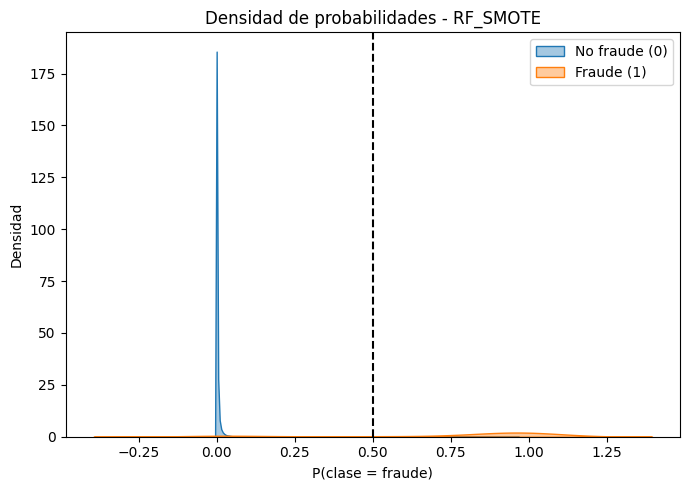

In [12]:
# =====================================================
# Celda A7: Density plot de probabilidades (mejor modelo)
# =====================================================

mejor_nombre = max(resultados.keys(), key=lambda k: resultados[k]["AUC_ROC"])
mejor_res = resultados[mejor_nombre]

print("Mejor modelo según AUC-ROC:", mejor_nombre)
print("AUC-ROC:", mejor_res["AUC_ROC"])

y_proba_best = mejor_res["y_proba"]

df_probs_A = pd.DataFrame({
    "y_true": y_test.values,
    "proba_fraude": y_proba_best
})

plt.figure(figsize=(7, 5))
sns.kdeplot(
    data=df_probs_A[df_probs_A["y_true"] == 0],
    x="proba_fraude",
    fill=True,
    alpha=0.4,
    label="No fraude (0)"
)
sns.kdeplot(
    data=df_probs_A[df_probs_A["y_true"] == 1],
    x="proba_fraude",
    fill=True,
    alpha=0.4,
    label="Fraude (1)"
)
plt.axvline(x=0.5, linestyle="--", color="black")
plt.title(f"Densidad de probabilidades - {mejor_nombre}")
plt.xlabel("P(clase = fraude)")
plt.ylabel("Densidad")
plt.legend()
plt.tight_layout()
plt.show()


El desbalanceo inluyo de manera importante el desempeño del modelo. El dataset original daba una falsa sensacion de buen desempeño por el alto accuracy que contienen, pero este mantiene una sansibilidad digamosle moderada hacia el fraude.
El undersampling mejoro la sensibilidad notablemente, pero esto sacrifica mucha informacion.
Aunque este mantuvo la estabiliad, pero su sensibilidad aun fue limitada. SMOTE ofrecio el mejor equilibrio entre sensibilidad y especificidad, logrando la mayor cpacidad de discriminativa y una PCA mas coherente. Por eso SMOTE resulto que fue la tecnica de balanceo mas efectiva para este problema

In [13]:
# =======================================
# PARTE B - TELCO CUSTOMER CHURN
# Celda B0: Imports y configuración
# =======================================

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    roc_auc_score,
    confusion_matrix
)

plt.style.use("default")
sns.set()

RANDOM_STATE = 42
OUTER_FOLDS = 5
INNER_FOLDS = 3


In [17]:
# =======================================
# Celda B1: Carga y preparación inicial
# =======================================

df_telco = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn .csv")

print("Dimensiones Telco:", df_telco.shape)
print(df_telco.head())

# Variable objetivo (Yes/No → 1/0)
y_telco = df_telco["Churn"].map({"No": 0, "Yes": 1}).astype(int)

# Guardar IDs para el top 2%
customer_ids = df_telco["customerID"].copy()

# Features
X_telco = df_telco.drop(["customerID", "Churn"], axis=1)

# Convertir TotalCharges a numérico
if "TotalCharges" in X_telco.columns:
    X_telco["TotalCharges"] = pd.to_numeric(X_telco["TotalCharges"], errors="coerce")

print("\nConteo de clases churn:")
print(y_telco.value_counts())
print("\nProporción de clases churn:")
print(y_telco.value_counts(normalize=True))


Dimensiones Telco: (7043, 21)
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV Stream

In [18]:
# =====================================================
# Celda B2: Preprocesamiento y definición del pipeline
# =====================================================

numeric_features = X_telco.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X_telco.select_dtypes(include=["object", "bool"]).columns.tolist()

# Pipeline numérico
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Pipeline categórico
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Ensamblar preprocessador
preprocessor_telco = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Modelo base RF
rf_telco = RandomForestClassifier(
    random_state=RANDOM_STATE,
    n_jobs=-1
)

# Pipeline completo
pipe_telco = Pipeline(steps=[
    ("preprocess", preprocessor_telco),
    ("rf", rf_telco)
])

# Hiperparámetros para búsqueda interna
param_grid_telco = {
    "rf__n_estimators": [200, 400],
    "rf__max_depth": [None, 10, 20],
    "rf__min_samples_split": [2, 5]
}

print("Pipeline listo.")


Pipeline listo.


In [19]:
# =====================================================
# Celda B3: Nested CV y probabilidades OOF
# =====================================================

outer_cv = StratifiedKFold(
    n_splits=OUTER_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE
)

inner_cv = StratifiedKFold(
    n_splits=INNER_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE
)

n_samples = len(X_telco)
oof_probas = np.zeros(n_samples)
oof_preds = np.zeros(n_samples, dtype=int)

all_cm_telco = np.zeros((2, 2), dtype=int)
all_aucs_telco = []

fold_idx = 1

for train_idx, test_idx in outer_cv.split(X_telco, y_telco):
    print(f"\n========== Outer Fold {fold_idx} ==========")
    
    X_train_fold = X_telco.iloc[train_idx]
    y_train_fold = y_telco.iloc[train_idx]
    X_test_fold  = X_telco.iloc[test_idx]
    y_test_fold  = y_telco.iloc[test_idx]
    
    # GridSearch interno
    grid = GridSearchCV(
        estimator=pipe_telco,
        param_grid=param_grid_telco,
        cv=inner_cv,
        scoring="roc_auc",
        n_jobs=-1
    )
    
    grid.fit(X_train_fold, y_train_fold)
    
    best_model_fold = grid.best_estimator_
    print("Mejores hiperparámetros:", grid.best_params_)
    
    # Probabilidades out-of-fold
    probas_fold = best_model_fold.predict_proba(X_test_fold)[:, 1]
    preds_fold = (probas_fold >= 0.5).astype(int)
    
    oof_probas[test_idx] = probas_fold
    oof_preds[test_idx] = preds_fold
    
    auc_fold = roc_auc_score(y_test_fold, probas_fold)
    cm_fold = confusion_matrix(y_test_fold, preds_fold)
    
    all_aucs_telco.append(auc_fold)
    all_cm_telco += cm_fold
    
    print("AUC fold:", auc_fold)
    print("Matriz de confusión fold:\n", cm_fold)
    
    fold_idx += 1

# Guardar resultados
oof_df_telco = pd.DataFrame({
    "customerID": customer_ids,
    "Churn_real": y_telco,
    "proba_churn_oof": oof_probas,
    "pred_churn_oof": oof_preds
})

oof_df_telco.to_csv("telco_oof_probas.csv", index=False)
print("\nArchivo guardado: telco_oof_probas.csv")



========== Outer Fold 1 ==========
Mejores hiperparámetros: {'rf__max_depth': 10, 'rf__min_samples_split': 5, 'rf__n_estimators': 400}
AUC fold: 0.8571378749128109
Matriz de confusión fold:
 [[937  98]
 [170 204]]

========== Outer Fold 2 ==========
Mejores hiperparámetros: {'rf__max_depth': 10, 'rf__min_samples_split': 5, 'rf__n_estimators': 400}
AUC fold: 0.8385595081247256
Matriz de confusión fold:
 [[930 105]
 [173 201]]

========== Outer Fold 3 ==========
Mejores hiperparámetros: {'rf__max_depth': 10, 'rf__min_samples_split': 5, 'rf__n_estimators': 400}
AUC fold: 0.85574930894624
Matriz de confusión fold:
 [[941  94]
 [175 199]]

========== Outer Fold 4 ==========
Mejores hiperparámetros: {'rf__max_depth': 10, 'rf__min_samples_split': 5, 'rf__n_estimators': 400}
AUC fold: 0.8251661032754402
Matriz de confusión fold:
 [[931 104]
 [199 174]]

========== Outer Fold 5 ==========
Mejores hiperparámetros: {'rf__max_depth': 10, 'rf__min_samples_split': 5, 'rf__n_estimators': 200}
AUC fo

In [20]:
# =====================================================
# Celda B4: Métricas globales Nested CV
# =====================================================

acc_global_telco = accuracy_score(y_telco, oof_preds)
sens_churn_telco = recall_score(y_telco, oof_preds, pos_label=1)
spec_nochurn_telco = recall_score(y_telco, oof_preds, pos_label=0)
auc_global_telco = roc_auc_score(y_telco, oof_probas)

print("\nMétricas globales Nested CV:")
print("Accuracy:", acc_global_telco)
print("Sensitivity (churn):", sens_churn_telco)
print("Specificity (no-churn):", spec_nochurn_telco)
print("AUC-ROC:", auc_global_telco)
print("Matriz de confusión acumulada:\n", all_cm_telco)

tabla_metricas_B = pd.DataFrame({
    "Accuracy": [acc_global_telco],
    "Sensitivity (churn)": [sens_churn_telco],
    "Specificity (no-churn)": [spec_nochurn_telco],
    "AUC-ROC": [auc_global_telco]
})

print("\nTabla Nested CV:")
print(tabla_metricas_B)



Métricas globales Nested CV:
Accuracy: 0.8017890103649014
Sensitivity (churn): 0.516318887105404
Specificity (no-churn): 0.9049091611905682
AUC-ROC: 0.8425526302128414
Matriz de confusión acumulada:
 [[4682  492]
 [ 904  965]]

Tabla Nested CV:
   Accuracy  Sensitivity (churn)  Specificity (no-churn)   AUC-ROC
0  0.801789             0.516319                0.904909  0.842553


In [21]:
# =====================================================
# Celda B5: Top 2% falsos positivos
# =====================================================

mask_nochurn = (y_telco == 0)

probas_nochurn = oof_probas[mask_nochurn]
idx_nochurn = np.where(mask_nochurn)[0]

n_top = max(1, int(0.02 * len(probas_nochurn)))

sorted_idx_local = np.argsort(-probas_nochurn)
top_local = sorted_idx_local[:n_top]
top_global_idx = idx_nochurn[top_local]

top2_fp_df = pd.DataFrame({
    "customerID": customer_ids.iloc[top_global_idx].values,
    "Churn_real": y_telco.iloc[top_global_idx].values,
    "proba_churn_oof": oof_probas[top_global_idx]
}).sort_values(by="proba_churn_oof", ascending=False)

print("\nTop 2% falsos positivos (No-churn con mayor probabilidad):")
print(top2_fp_df.head(10))

top2_fp_df.to_csv("telco_top2_percent_falsos_positivos.csv", index=False)
print("Archivo guardado: telco_top2_percent_falsos_positivos.csv")



Top 2% falsos positivos (No-churn con mayor probabilidad):
   customerID  Churn_real  proba_churn_oof
0  7577-SWIFR           0         0.882279
1  7439-DKZTW           0         0.880616
2  1452-VOQCH           0         0.862762
3  5150-ITWWB           0         0.860874
4  3878-AVSOQ           0         0.857816
5  0021-IKXGC           0         0.857191
6  5542-TBBWB           0         0.856005
7  4912-PIGUY           0         0.851367
8  2545-EBUPK           0         0.850612
9  9603-OAIHC           0         0.837847
Archivo guardado: telco_top2_percent_falsos_positivos.csv


In [24]:
# =====================================================
# Celda B6: Análisis cuantitativo grupo alto riesgo
# =====================================================

grupo_alto_riesgo = df_telco.iloc[top_global_idx].copy()
resto_nochurn = df_telco[mask_nochurn & ~df_telco.index.isin(top_global_idx)].copy()

print("Tamaño grupo alto riesgo:", len(grupo_alto_riesgo))
print("Tamaño resto no-churn:", len(resto_nochurn))

# Comparación básica de variables numéricas
for col in ["tenure", "MonthlyCharges", "TotalCharges"]:
    if col in df_telco.columns:
        print(f"\nPromedio {col}:")
        print(
            "Alto riesgo:",
            pd.to_numeric(grupo_alto_riesgo[col], errors="coerce").mean()
        )
        print(
            "Resto no-churn:",
            pd.to_numeric(resto_nochurn[col], errors="coerce").mean()
        )

# Distribución de contrato
if "Contract" in df_telco.columns:
    print("\nDistribución Contract (alto riesgo):")
    print(grupo_alto_riesgo["Contract"].value_counts(normalize=True))
    
    print("\nDistribución Contract (resto no-churn):")
    print(resto_nochurn["Contract"].value_counts(normalize=True))



Tamaño grupo alto riesgo: 103
Tamaño resto no-churn: 5071

Promedio tenure:
Alto riesgo: 4.378640776699029
Resto no-churn: 38.24413330704003

Promedio MonthlyCharges:
Alto riesgo: 78.43398058252428
Resto no-churn: 60.916397160323406

Promedio TotalCharges:
Alto riesgo: 375.39223300970883
Resto no-churn: 2599.718656126482

Distribución Contract (alto riesgo):
Contract
Month-to-month    1.0
Name: proportion, dtype: float64

Distribución Contract (resto no-churn):
Contract
Month-to-month    0.417472
Two year          0.324788
One year          0.257740
Name: proportion, dtype: float64


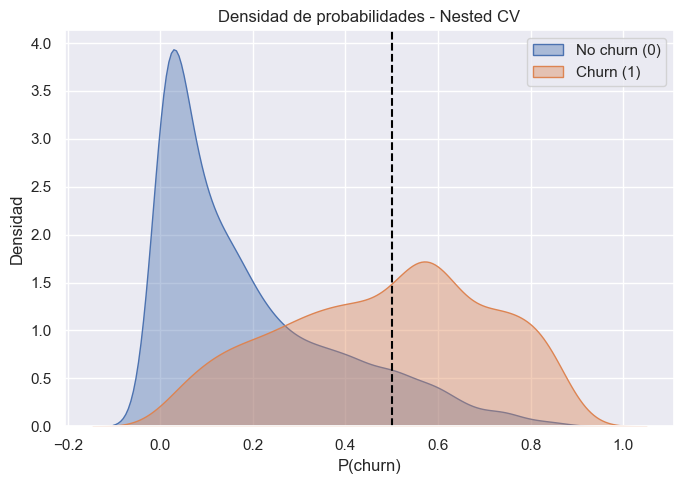

In [25]:
# =====================================================
# Celda B7: Density plot de churn (Nested CV)
# =====================================================

df_probs_B = pd.DataFrame({
    "y_true": y_telco,
    "proba_churn": oof_probas
})

plt.figure(figsize=(7, 5))
sns.kdeplot(
    data=df_probs_B[df_probs_B["y_true"] == 0],
    x="proba_churn",
    fill=True,
    alpha=0.4,
    label="No churn (0)"
)
sns.kdeplot(
    data=df_probs_B[df_probs_B["y_true"] == 1],
    x="proba_churn",
    fill=True,
    alpha=0.4,
    label="Churn (1)"
)
plt.axvline(x=0.5, linestyle="--", color="black")
plt.title("Densidad de probabilidades - Nested CV")
plt.xlabel("P(churn)")
plt.ylabel("Densidad")
plt.legend()
plt.tight_layout()
plt.show()
